In [1]:
lazy import os
lazy from dotenv import load_dotenv
lazy import numpy as np
lazy import random
lazy import matplotlib.pyplot as plt

In [2]:
load_dotenv()

True

In [3]:
DATASET_PATH = os.getenv("DATASET_PATH_1")
if DATASET_PATH and os.path.exists(DATASET_PATH):
    data = np.load(DATASET_PATH)
else:
    print("Erro: Caminho não encontrado")

In [4]:
print(data)

[[[ 547.91209711 -122.2431205     1.        ]]

 [[ 717.19583982  394.73605812    0.        ]]

 [[-811.64530422  951.24470327    0.        ]]

 ...

 [[ -49.38876423  507.54135929    0.        ]]

 [[-429.75519917 -329.90624499    1.        ]]

 [[ 691.39880129   40.14382452    1.        ]]]


In [5]:
data = data.squeeze()

In [6]:
class Neuron:
    def __init__(self, dataset):
        self.dataset = dataset
        self.X = np.insert(dataset[:, :-1], 0, 1, axis=1)
        self.Yd = dataset[:, -1]
        self.weights = [0.0, 0.0, 0.0]
        self.learning_rate = 0.1
        self.w_adjust_count = 0
        self.epochs = 0
        self.w_changes = []

    def threshold(self, inputs, weights):
        if len(inputs) != len(weights):
            raise ValueError("O vetor de entradas deve ter a mesma quantidade de elementos que o de pesos")
        v = 0.0
        n = len(inputs)
        for i in range(n):
            v+= inputs[i]*weights[i]
        if v < 0:
            return 0
        elif v >= 0:
            return 1

    def init_weights(self):
        for i in range(3):
            self.weights[i] = random.uniform(-0.5, 0.5)
        print(f"Vetor inicial de pesos: ({self.weights[0]},{self.weights[1]}, {self.weights[2]})")

    def adjust_weights(self, inputs, weights, error):
        new_weights = []
        for wi, xi in zip(weights, inputs):
            new_weights.append(wi + self.learning_rate*error*xi)
        return new_weights

    def train(self, inputs, targets):
        self.init_weights()
        while True:
            had_error = False
            for xi, yi in zip(inputs, targets):
                output = self.threshold(xi, self.weights)
                error = yi - output
                if error != 0:
                    had_error = True
                    self.w_changes.append(self.weights)
                    self.weights = self.adjust_weights(xi, self.weights, error)
                    self.w_adjust_count += 1
            self.epochs += 1
            if not had_error:
                break

    def execute(self):
        self.train(self.X, self.Yd)
        print(f"Vetor final de pesos: {self.weights}")
        print(f"Número total de ajustes no vetor de pesos: {self.w_adjust_count}")
        print(f"Número de épocas até a convergência: {self.epochs}")
        self.plot()

    def plot(self):
        w0 = self.weights[0]
        w1 = self.weights[1]
        w2 = self.weights[2]
    
        x1_min = self.X[:, 1].min()
        x1_max = self.X[:, 1].max()
        
        x = np.array([x1_min, x1_max])
        y = -(w0 + w1 * x) / w2
    
        y0 = self.X[self.Yd == 0]
        y1 = self.X[self.Yd == 1]

        plt.scatter(y0[:, 1], y0[:, 2], color="red", label="Classe 0", s=20)
        plt.scatter(y1[:, 1], y1[:, 2], color="blue", label="Classe 1", s=20)
    
        plt.plot(x, y, color="purple", label="Reta que separa as classes")
        plt.xlabel("x1")
        plt.ylabel("x2")
        plt.legend()
        plt.show()
        

In [7]:
neuron = Neuron(data)

Vetor inicial de pesos: (-0.1383781119000942,-0.4594307741370296, 0.10729685495354147)
Vetor final de pesos: [np.float64(-0.03837811190009424), np.float64(69.20293567143526), np.float64(-353.40259072624974)]
Número total de ajustes no vetor de pesos: 41
Número de épocas até a convergência: 3


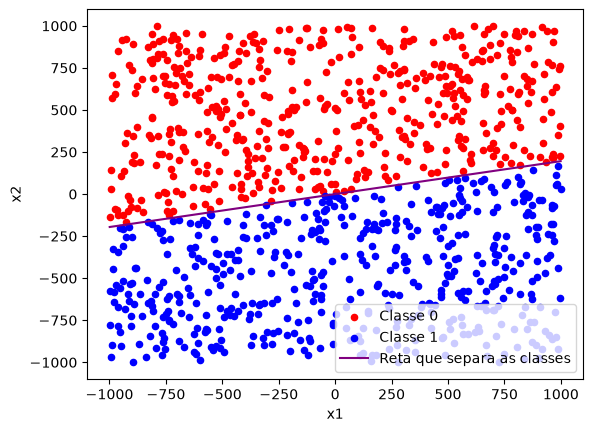

In [8]:
neuron.execute()